<a href="https://colab.research.google.com/github/bharati-cse/DAV-LAB/blob/main/prg7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset:
   Study Hours  Marks Obtained
0            1              35
1            2              40
2            3              50
3            4              55
4            5              60
5            6              65
6            7              70
7            8              80
8            9              85
9           10              95

Intercept: 28.66
Coefficient: 6.38
RMSE: 1.26
R² Score: 0.9969
Predicted marks for 7 study hours: 73.32


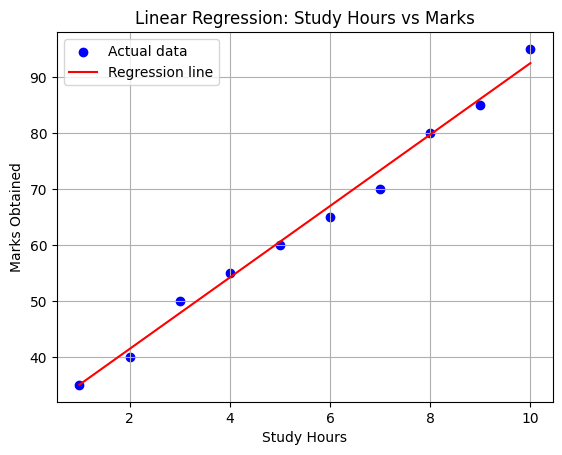

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Create sample dataset
data = {
    'Study Hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Marks Obtained': [35, 40, 50, 55, 60, 65, 70, 80, 85, 95]
}

df = pd.DataFrame(data)

print("Dataset:")
print(df)

# 2. Define independent and dependent variables
X = df[['Study Hours']]
y = df['Marks Obtained']

# 3. Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Predict marks
y_pred = model.predict(X_test)

# 6. Calculate RMSE and R² Score
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nIntercept:", round(model.intercept_, 2))
print("Coefficient:", round(model.coef_[0], 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 4))

# 7. Predict marks for a student studying 7 hours
hours = pd.DataFrame({'Study Hours': [7]})
predicted_marks = model.predict(hours)

print("Predicted marks for 7 study hours:",
      round(predicted_marks[0], 2))

# 8. Visualize the regression line
plt.scatter(X, y, color='blue', label='Actual data')
plt.plot(X, model.predict(X), color='red',
         label='Regression line')

plt.xlabel('Study Hours')
plt.ylabel('Marks Obtained')
plt.title('Linear Regression: Study Hours vs Marks')
plt.legend()
plt.grid(True)
plt.show()

Dataset:
   Study Hours  Attendance  Sleep Hours  Marks Obtained
0            1          60            5              30
1            2          65            6              35
2            3          70            7              45
3            4          75            6              50
4            5          80            8              60
5            6          85            7              65
6            7          88            8              72
7            8          90            7              80
8            9          95            8              88
9           10          98            9              95

RMSE: 1.93
R² Score: 0.9947


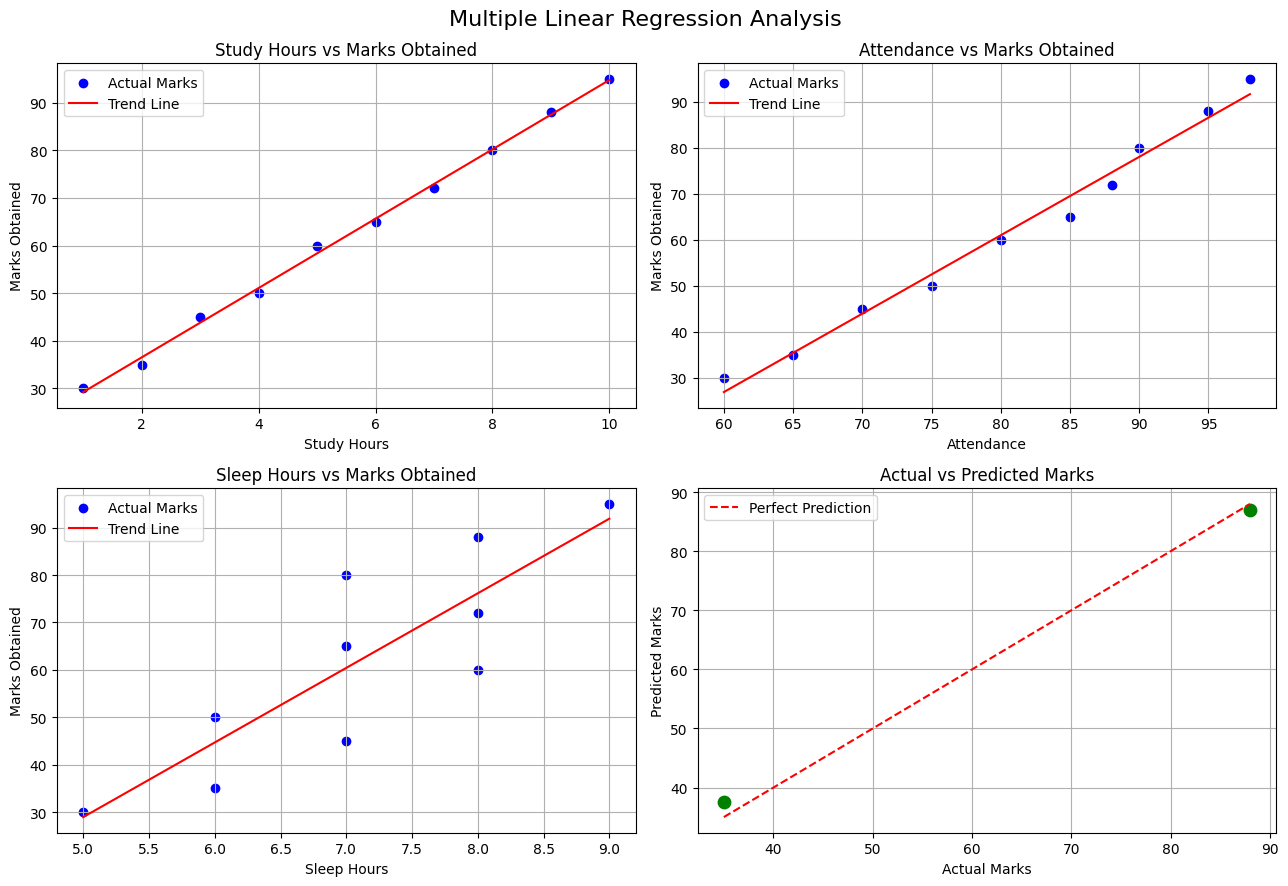

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Create sample dataset
data = {
    'Study Hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Attendance': [60, 65, 70, 75, 80, 85, 88, 90, 95, 98],
    'Sleep Hours': [5, 6, 7, 6, 8, 7, 8, 7, 8, 9],
    'Marks Obtained': [30, 35, 45, 50, 60, 65, 72, 80, 88, 95]
}

df = pd.DataFrame(data)

print("Dataset:")
print(df)

# 2. Define variables
X = df[['Study Hours', 'Attendance', 'Sleep Hours']]
y = df['Marks Obtained']

# 3. Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Train Multiple Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Predict marks
y_pred = model.predict(X_test)

# 6. Calculate RMSE and R²
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nRMSE:", round(rmse, 2))
print("R² Score:", round(r2, 4))

# 7. Plot all independent variables against marks
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

features = ['Study Hours', 'Attendance', 'Sleep Hours']

for i, feature in enumerate(features):
    ax = axes.flat[i]

    # Scatter plot of actual data
    ax.scatter(df[feature], y, color='blue', label='Actual Marks')

    # Fit a simple trend line for visualization only
    z = np.polyfit(df[feature], y, 1)
    p = np.poly1d(z)

    x_line = np.linspace(df[feature].min(), df[feature].max(), 100)
    ax.plot(x_line, p(x_line), color='red', label='Trend Line')

    ax.set_xlabel(feature)
    ax.set_ylabel('Marks Obtained')
    ax.set_title(f'{feature} vs Marks Obtained')
    ax.legend()
    ax.grid(True)

# 8. Actual vs Predicted graph
axes[1, 1].scatter(y_test, y_pred, color='green', s=80)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

axes[1, 1].plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    label='Perfect Prediction'
)

axes[1, 1].set_xlabel('Actual Marks')
axes[1, 1].set_ylabel('Predicted Marks')
axes[1, 1].set_title('Actual vs Predicted Marks')
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.suptitle('Multiple Linear Regression Analysis', fontsize=16)
plt.tight_layout()
plt.show()